# Imports

In [1]:
import seaborn as sns
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Load data

In [2]:
def replace_negatives_and_zeros_with_row_max(df):
    """
    Replaces negative numbers and zeros in each row of a DataFrame with the maximum value of that row.

    Args:
        df (pd.DataFrame): Input DataFrame.

    Returns:
        pd.DataFrame: DataFrame with modified values.
    """
    # Add a count of how many values have a zero
    count_zero = df.apply(lambda row: (row == 0).sum(), axis=1)
    print("Number of values changed:", count_zero.sum())
    
    # Iterate through each row
    for index, row in df.iterrows():
        max_val = row.max()
        df.loc[index] = row.apply(lambda x: max_val if x <= 0 else x)

    return df

def replace_negatives_and_zeros_with_row_and_column_max(df):
    """
    Replaces negative numbers and zeros in each row and column of a DataFrame with the maximum value of that row and column.

    Args:
        df (pd.DataFrame): Input DataFrame.

    Returns:
        pd.DataFrame: DataFrame with modified values.
    """
    # First, find the max values for each row and column before modifying
    row_max_values = df.max(axis=1)
    column_max_values = df.max()
    print("Acid Chlorides")
    print(row_max_values)
    print("\nAmines")
    print(column_max_values)
    
    # Count the number of zeros and negative values
    count_zero_negative = df.apply(lambda row: ((row == 0) | (row <= 0)).sum(), axis=1)
    print("Number of values changed:", count_zero_negative.sum())
    
    # Iterate through each row
    for index, row in df.iterrows():
        row_max = row_max_values[index]
        
        # Replace zeros and negatives with the max value between row max and corresponding column max
        # df.loc[index] = row.apply(lambda x, col=row: max(row_max, column_max_values[col.name]) if x <= 0 else x)
        for col in df.columns:
            if df.loc[index, col] <= 0:
                print(f'replacing amine = {col} and acid chloride = {index} by', row_max, column_max_values[col], max(row_max, column_max_values[col]))
                df.loc[index, col] = max(row_max, column_max_values[col])

    return df



In [ ]:
all_df = pd.read_csv("data/all_raw_data_with_labels.csv", index_col=0)
all_df.rename(columns={"2": "Controls"}, inplace=True)
train_df = all_df.iloc[:32, :35]
train_df

,Acid Labels,tertbutylamine,Controls,4-fluoroaniline,p-anisidine,aniline,"2,4,6-trimethylaniline",4-heptylaniline,"2,6-diisopropylaniline",dicyclohexylamine,...,N-isopropylcyclohexanamine,o-anisidine,triphenylmethanamine,"2,6-dimethylaniline","tertbutyl-3,5-dimethylpiperazin-1-carboxylate",3-anilinopropionitrile,2-fluoroaniline,3-methoxyaniline,4-aminobenzophenone,4-(4-fluorophenoxy)aniline
Amine Labels,NaN,1.000000,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,8.000000,9.000000,...,27.000000,28.000000,29.000000,30.000000,31.000000,32.000000,33.000000,35.000000,36.000000,37.000000
4-fluorobenzoyl chloride-average,1.0,521.942558,11.763533,19.593600,425.146340,17.876277,16.011251,65.730510,12.642810,16.539027,...,7.907942,38.572172,7.055067,6.090463,16.732790,6.521297,7.587329,14.548795,9.486291,21.811952
benzoyl chloride,2.0,4.928887,7.017544,20.539425,290.909091,15.978581,17.139130,50.760668,8.761154,11.727137,...,13.096060,24.406085,8.936616,8.084680,8.102404,7.165362,7.804959,11.379956,8.098012,28.932387
4-tertbutyl benzoyl chloride,3.0,2.005995,3.638350,7.999518,89.411564,8.106494,8.786975,26.826229,3.798261,4.076398,...,5.497678,10.457711,4.830786,4.901179,4.849725,3.538230,4.310531,6.260919,5.913205,13.960309
"2,4-difluorobenzoyl chloride",4.0,30.750751,40.345423,323.217031,1462.857143,436.447958,146.420664,557.948718,44.511715,90.326241,...,106.222781,336.130581,72.908024,98.773714,189.226765,91.454813,73.306799,260.423164,72.677543,489.753567
4-trifluoromethylbenzoyl chloride,5.0,41.638791,39.128978,172.307692,0.000000,65.367281,45.714286,192.876712,40.593792,82.212661,...,210.507726,554.218134,192.682129,226.171755,345.433466,202.392919,184.947093,204.937388,180.462250,126.430518
4-phenylbenzoyl chloride,6.0,5.654085,4.505172,13.551685,212.067260,13.364486,11.570127,51.055276,6.833346,8.758108,...,8.329712,21.071030,5.338186,4.355688,14.497048,4.122270,5.216105,9.082512,8.176088,19.326813
thiophene-2-carbonyl chloride,7.0,5.240550,16.838853,12.036557,115.898968,7.563419,9.642732,19.971276,13.464360,11.722428,...,22.512424,10.704220,23.486239,23.144514,14.351013,24.208457,23.217015,21.816947,27.742179,10.645261
2-naphthoyl chloride,8.0,4.257202,5.887430,15.643965,199.315445,15.845143,13.864365,69.241122,6.376956,11.872184,...,9.993060,27.485311,6.524925,3.465254,5.251694,4.596741,6.262273,14.027989,6.593146,26.673138
p-anisoyl chloride,9.0,1.672351,4.708404,4.302569,54.786981,4.205155,4.415322,14.576116,3.931116,6.563238,...,5.763878,4.092517,7.887213,6.572477,2.224113,5.023844,8.279060,3.001917,4.695691,4.729022


In [4]:
for i,col in enumerate(train_df.columns):
    print(i+1, col)

1 Acid Labels
2 tertbutylamine
3 Controls
4 4-fluoroaniline
5 p-anisidine
6 aniline
7 2,4,6-trimethylaniline
8 4-heptylaniline
9 2,6-diisopropylaniline
10 dicyclohexylamine
11 4-hexylaniline
12 2-methylthioaniline
13 2-aminobiphenyl
14 4-tertbutylaniline
15 diisopropylamine
16 4-bromoaniline
17 2-methylpiperidine
18 8-aminoquinoline
19 3-aminoacetophenone
20 morpholine
21 2-methoxy-5-CF3-aniline
22 2-(2-methoxyethoxy)aniline
23 3 amino pentane
24 2,6-dimethylpiperidine
25 4-vinylaniline
26 p-toluidine
27 m-toluidine
28 N-isopropylcyclohexanamine
29 o-anisidine
30 triphenylmethanamine
31 2,6-dimethylaniline
32 tertbutyl-3,5-dimethylpiperazin-1-carboxylate
33 3-anilinopropionitrile
34 2-fluoroaniline
35 3-methoxyaniline
36 4-aminobenzophenone
37 4-(4-fluorophenoxy)aniline


In [5]:
df_hte_rates = pd.read_csv("data/hte_rates.csv")
df_hte_rates

,reaction,acid_chlorides,amines,HTE_rate,HTE_lnk,amine_smiles,acid_smiles,test splits
0,rxn_01_01,1,1,521.942558,2.717623,CC(N)(C)C,ClC(c1ccc(F)cc1)=O,TRAIN
1,rxn_01_03,1,3,19.593600,1.292114,Nc1ccc(F)cc1,ClC(c1ccc(F)cc1)=O,TRAIN
2,rxn_01_04,1,4,425.146340,2.628538,COc1ccc(N)cc1,ClC(c1ccc(F)cc1)=O,TRAIN
3,rxn_01_05,1,5,17.876277,1.252277,Nc1ccccc1,ClC(c1ccc(F)cc1)=O,TRAIN
4,rxn_01_07,1,7,65.730510,1.817767,CCCCCCCc1ccc(N)cc1,ClC(c1ccc(F)cc1)=O,TRAIN
...,...,...,...,...,...,...,...,...
763,rxn_43_46,43,46,1549.473684,3.190184,NC1=CC2=C(C=C1)C3=CC=CC=C3C2,ClC(C1CCOCC1)=O,TEST2
764,rxn_43_47,43,47,1174.135338,3.069718,NC1=CC=C(OC2=CC=CC=C2)C=C1,ClC(C1CCOCC1)=O,TEST2
765,rxn_43_48,43,48,365.982405,2.563460,NC1=C(N2CCOCC2)C=CC=C1,ClC(C1CCOCC1)=O,TEST2
766,rxn_45_03,45,3,10000.000000,4.000000,Nc1ccc(F)cc1,ClC(COCC1=CC=CC=C1)=O,TEST1


In [6]:
train_df.iloc[0, 1:].astype(int)

tertbutylamine                                    1
Controls                                          2
4-fluoroaniline                                   3
p-anisidine                                       4
aniline                                           5
2,4,6-trimethylaniline                            6
4-heptylaniline                                   7
2,6-diisopropylaniline                            8
dicyclohexylamine                                 9
4-hexylaniline                                   10
2-methylthioaniline                              11
2-aminobiphenyl                                  12
4-tertbutylaniline                               13
diisopropylamine                                 14
4-bromoaniline                                   15
2-methylpiperidine                               16
8-aminoquinoline                                 17
3-aminoacetophenone                              18
morpholine                                       19
2-methoxy-5-

In [7]:
# Join train_df with df_hte_rates by matching the amine labels
# First, get the amine labels from train_df (excluding the header row)
amine_labels = train_df.iloc[0, 1:].astype(int)

# Join with df_hte_rates on the 'amines' column, keeping only the first match per row
joined_df_amines = df_hte_rates.merge(amine_labels.reset_index(), 
                              left_on='amines', 
                              right_on=amine_labels.name, 
                              how='inner').drop_duplicates(subset=['amines'], keep='first')
joined_df_amines.sort_values(by='amines', inplace=True)
amines_smiles = joined_df_amines[["index", "amine_smiles"]].reset_index(drop=True)
amines_smiles.to_csv("data/amines_smiles.csv", index=False)

In [8]:
acid_labels = train_df.iloc[1:, 0].astype(int)

joined_df_acids = df_hte_rates.merge(acid_labels.reset_index(), 
                              left_on='acid_chlorides', 
                              right_on=acid_labels.name, 
                              how='inner').drop_duplicates(subset=['acid_chlorides'], keep='first')
joined_df_acids.sort_values(by='acid_chlorides', inplace=True)
acids_smiles = joined_df_acids[["index", "acid_smiles"]].reset_index(drop=True)
acids_smiles.to_csv("data/acids_smiles.csv", index=False)

In [9]:
# Remove the "Acid Labels" column and "Amine Labels" row
train_df = train_df.drop(columns=['Acid Labels'])
train_df = train_df.drop(index=['Amine Labels'])
train_df

,tertbutylamine,Controls,4-fluoroaniline,p-anisidine,aniline,"2,4,6-trimethylaniline",4-heptylaniline,"2,6-diisopropylaniline",dicyclohexylamine,4-hexylaniline,...,N-isopropylcyclohexanamine,o-anisidine,triphenylmethanamine,"2,6-dimethylaniline","tertbutyl-3,5-dimethylpiperazin-1-carboxylate",3-anilinopropionitrile,2-fluoroaniline,3-methoxyaniline,4-aminobenzophenone,4-(4-fluorophenoxy)aniline
4-fluorobenzoyl chloride-average,521.942558,11.763533,19.593600,425.146340,17.876277,16.011251,65.730510,12.642810,16.539027,67.061713,...,7.907942,38.572172,7.055067,6.090463,16.732790,6.521297,7.587329,14.548795,9.486291,21.811952
benzoyl chloride,4.928887,7.017544,20.539425,290.909091,15.978581,17.139130,50.760668,8.761154,11.727137,52.389381,...,13.096060,24.406085,8.936616,8.084680,8.102404,7.165362,7.804959,11.379956,8.098012,28.932387
4-tertbutyl benzoyl chloride,2.005995,3.638350,7.999518,89.411564,8.106494,8.786975,26.826229,3.798261,4.076398,28.022599,...,5.497678,10.457711,4.830786,4.901179,4.849725,3.538230,4.310531,6.260919,5.913205,13.960309
"2,4-difluorobenzoyl chloride",30.750751,40.345423,323.217031,1462.857143,436.447958,146.420664,557.948718,44.511715,90.326241,727.047216,...,106.222781,336.130581,72.908024,98.773714,189.226765,91.454813,73.306799,260.423164,72.677543,489.753567
4-trifluoromethylbenzoyl chloride,41.638791,39.128978,172.307692,0.000000,65.367281,45.714286,192.876712,40.593792,82.212661,283.181818,...,210.507726,554.218134,192.682129,226.171755,345.433466,202.392919,184.947093,204.937388,180.462250,126.430518
4-phenylbenzoyl chloride,5.654085,4.505172,13.551685,212.067260,13.364486,11.570127,51.055276,6.833346,8.758108,51.034483,...,8.329712,21.071030,5.338186,4.355688,14.497048,4.122270,5.216105,9.082512,8.176088,19.326813
thiophene-2-carbonyl chloride,5.240550,16.838853,12.036557,115.898968,7.563419,9.642732,19.971276,13.464360,11.722428,23.360419,...,22.512424,10.704220,23.486239,23.144514,14.351013,24.208457,23.217015,21.816947,27.742179,10.645261
2-naphthoyl chloride,4.257202,5.887430,15.643965,199.315445,15.845143,13.864365,69.241122,6.376956,11.872184,70.190921,...,9.993060,27.485311,6.524925,3.465254,5.251694,4.596741,6.262273,14.027989,6.593146,26.673138
p-anisoyl chloride,1.672351,4.708404,4.302569,54.786981,4.205155,4.415322,14.576116,3.931116,6.563238,11.164686,...,5.763878,4.092517,7.887213,6.572477,2.224113,5.023844,8.279060,3.001917,4.695691,4.729022
pivaloyl chloride,0.720721,3.740117,35.616633,458.594104,33.371071,2.870455,154.840353,3.244340,6.218518,119.369234,...,7.334436,128.202692,3.444914,1.473538,3.927321,3.110097,2.582513,22.347318,3.178429,55.109261


In [10]:
#### replace negatives and zeros with row max
train_mod_df = replace_negatives_and_zeros_with_row_max(train_df)

#### convert rates to log10
# train_df = np.log10(train_mod_df)


Number of values changed: 62


In [11]:
#### For the original dataframe: Final dataframe
# Calculate the average values for each column
column_averages = train_df.median()

# Sort columns by average values (ascending order)
sorted_columns = column_averages.sort_values()

# Sort rows by average values (ascending order)
row_averages = train_df.median(axis=1)
sorted_rows = row_averages.sort_values(ascending=False)

sorted_final = train_df.loc[sorted_rows.index, sorted_columns.index]


sorted_final

,triphenylmethanamine,3-anilinopropionitrile,4-bromoaniline,"2,6-dimethylaniline",Controls,tertbutylamine,2-fluoroaniline,4-aminobenzophenone,"2,6-diisopropylaniline",2-methylthioaniline,...,o-anisidine,2-(2-methoxyethoxy)aniline,4-tertbutylaniline,4-hexylaniline,4-heptylaniline,p-toluidine,p-anisidine,3 amino pentane,2-methylpiperidine,morpholine
acetyl chloride,1181.538462,1496.692913,3840.000000,1496.692913,518.871701,505.263158,1234.285714,1781.443299,514.663403,937.674419,...,3840.000000,1417.142857,2400.000000,2468.571429,2194.285714,213.333333,7680.000000,7680.000000,1920.000000,7680.000000
dodecanoyl chloride,199.342021,513.896296,333.747471,318.492936,368.625181,213.333333,430.121458,199.342021,376.242424,337.828140,...,930.909091,2159.589744,1652.093023,1255.672515,1396.363636,1137.777778,5120.000000,5120.000000,5120.000000,5120.000000
heptanoyl chloride,190.358348,230.592499,402.797203,230.383961,203.716651,92.258533,189.866667,218.789990,454.471910,249.890664,...,1280.000000,3840.000000,1378.461538,1236.610169,1076.409449,853.333333,1280.000000,5120.000000,5120.000000,512.000000
cinnamoyl chloride,392.767123,329.720535,596.985743,354.042553,344.615385,2640.000000,226.881517,536.774194,182.018349,178.760269,...,205.038283,303.404573,339.201311,747.936508,450.496772,205.038283,937.674419,2640.000000,2640.000000,2640.000000
valeroyl chloride,136.867229,161.157187,242.834744,176.961423,207.863248,123.624428,137.603801,133.515018,295.384615,297.359940,...,482.779156,584.566929,699.102902,906.905830,1024.000000,722.051282,1462.857143,1462.857143,640.000000,1462.857143
4-nitrobenzoyl chloride,71.151204,74.622543,158.654733,83.254174,93.844122,1462.857143,63.183372,55.479549,125.033332,86.735510,...,695.725594,1388.936170,1462.857143,1144.242424,908.387097,1462.857143,1462.857143,1462.857143,1462.857143,1462.857143
4-trifluoromethylbenzoyl chloride,192.682129,202.392919,64.464704,226.171755,39.128978,41.638791,184.947093,180.462250,40.593792,43.872318,...,554.218134,362.057143,458.824378,283.181818,192.876712,975.238095,975.238095,975.238095,975.238095,975.238095
2-phenylbutyryl chloride,64.339295,58.951487,106.850258,23.795390,30.646113,12.887917,27.171462,32.556256,35.798152,103.761400,...,845.913043,597.992278,3840.000000,2074.482759,2108.235294,1462.857143,3840.000000,3840.000000,3840.000000,3840.000000
"2,4-difluorobenzoyl chloride",72.908024,91.454813,88.383871,98.773714,40.345423,30.750751,73.306799,72.677543,44.511715,48.186197,...,336.130581,375.822725,615.569189,727.047216,557.948718,1024.000000,1462.857143,1024.000000,1462.857143,1462.857143
"2,4-dichlorobenzoyl chloride",26.246409,38.811432,69.017298,26.109789,22.546640,11.965178,40.229355,29.668095,20.743444,42.547325,...,191.632902,379.364758,621.719457,562.199711,457.548447,478.336542,2579.393939,2579.393939,2579.393939,2579.393939


In [12]:
sorted_final.to_csv("data/sorted_final_rates.csv")


In [13]:
def rate_heatmap(df):
    from matplotlib.colors import SymLogNorm
    # Create a heatmap
    plt.figure(figsize=(40, 30))
    cmap_color='cividis'  #'PuBuGn'  #'crest_r' #'gnuplot'
    
    # SymLogNorm with linear region around 100
    norm = SymLogNorm(linthresh=10, vmin=df.min().min(), vmax=df.max().max())
    
    sns.heatmap(df, annot=False, cmap=cmap_color, linewidths=0.5, 
                linecolor='gray', norm=norm)
    
    # sns.heatmap(df, annot=False, cmap=cmap_color, linewidths=0.5, linecolor='gray', norm=LogNorm())

    # Customize labels
    plt.title("Rate of Amide Bond Formation at Room Temperature in (1 / M * min)")
    plt.xticks(rotation=45, ha='right')
    plt.tick_params(axis='both', which='major', labelsize=12)
    plt.ylabel("Acid Chlorides")
    plt.xlabel("Amines")
    plt.yticks(rotation=0)   
    plt.rc('axes', labelsize=40)
    plt.rc('axes', titlesize=40) 
    plt.rc('font', size=30)
    # Add a colorbar label
    cbar = plt.gcf().axes[-1]  # Get the colorbar axes
    cbar.set_ylabel("Rate (1 / M * min)", size=30, labelpad=20)

    # save plot
    # plt.savefig(f'plots/hte_rate_heatmap_{cmap_color}.png', dpi=300)

    # Show the plot
    plt.show()
    
    

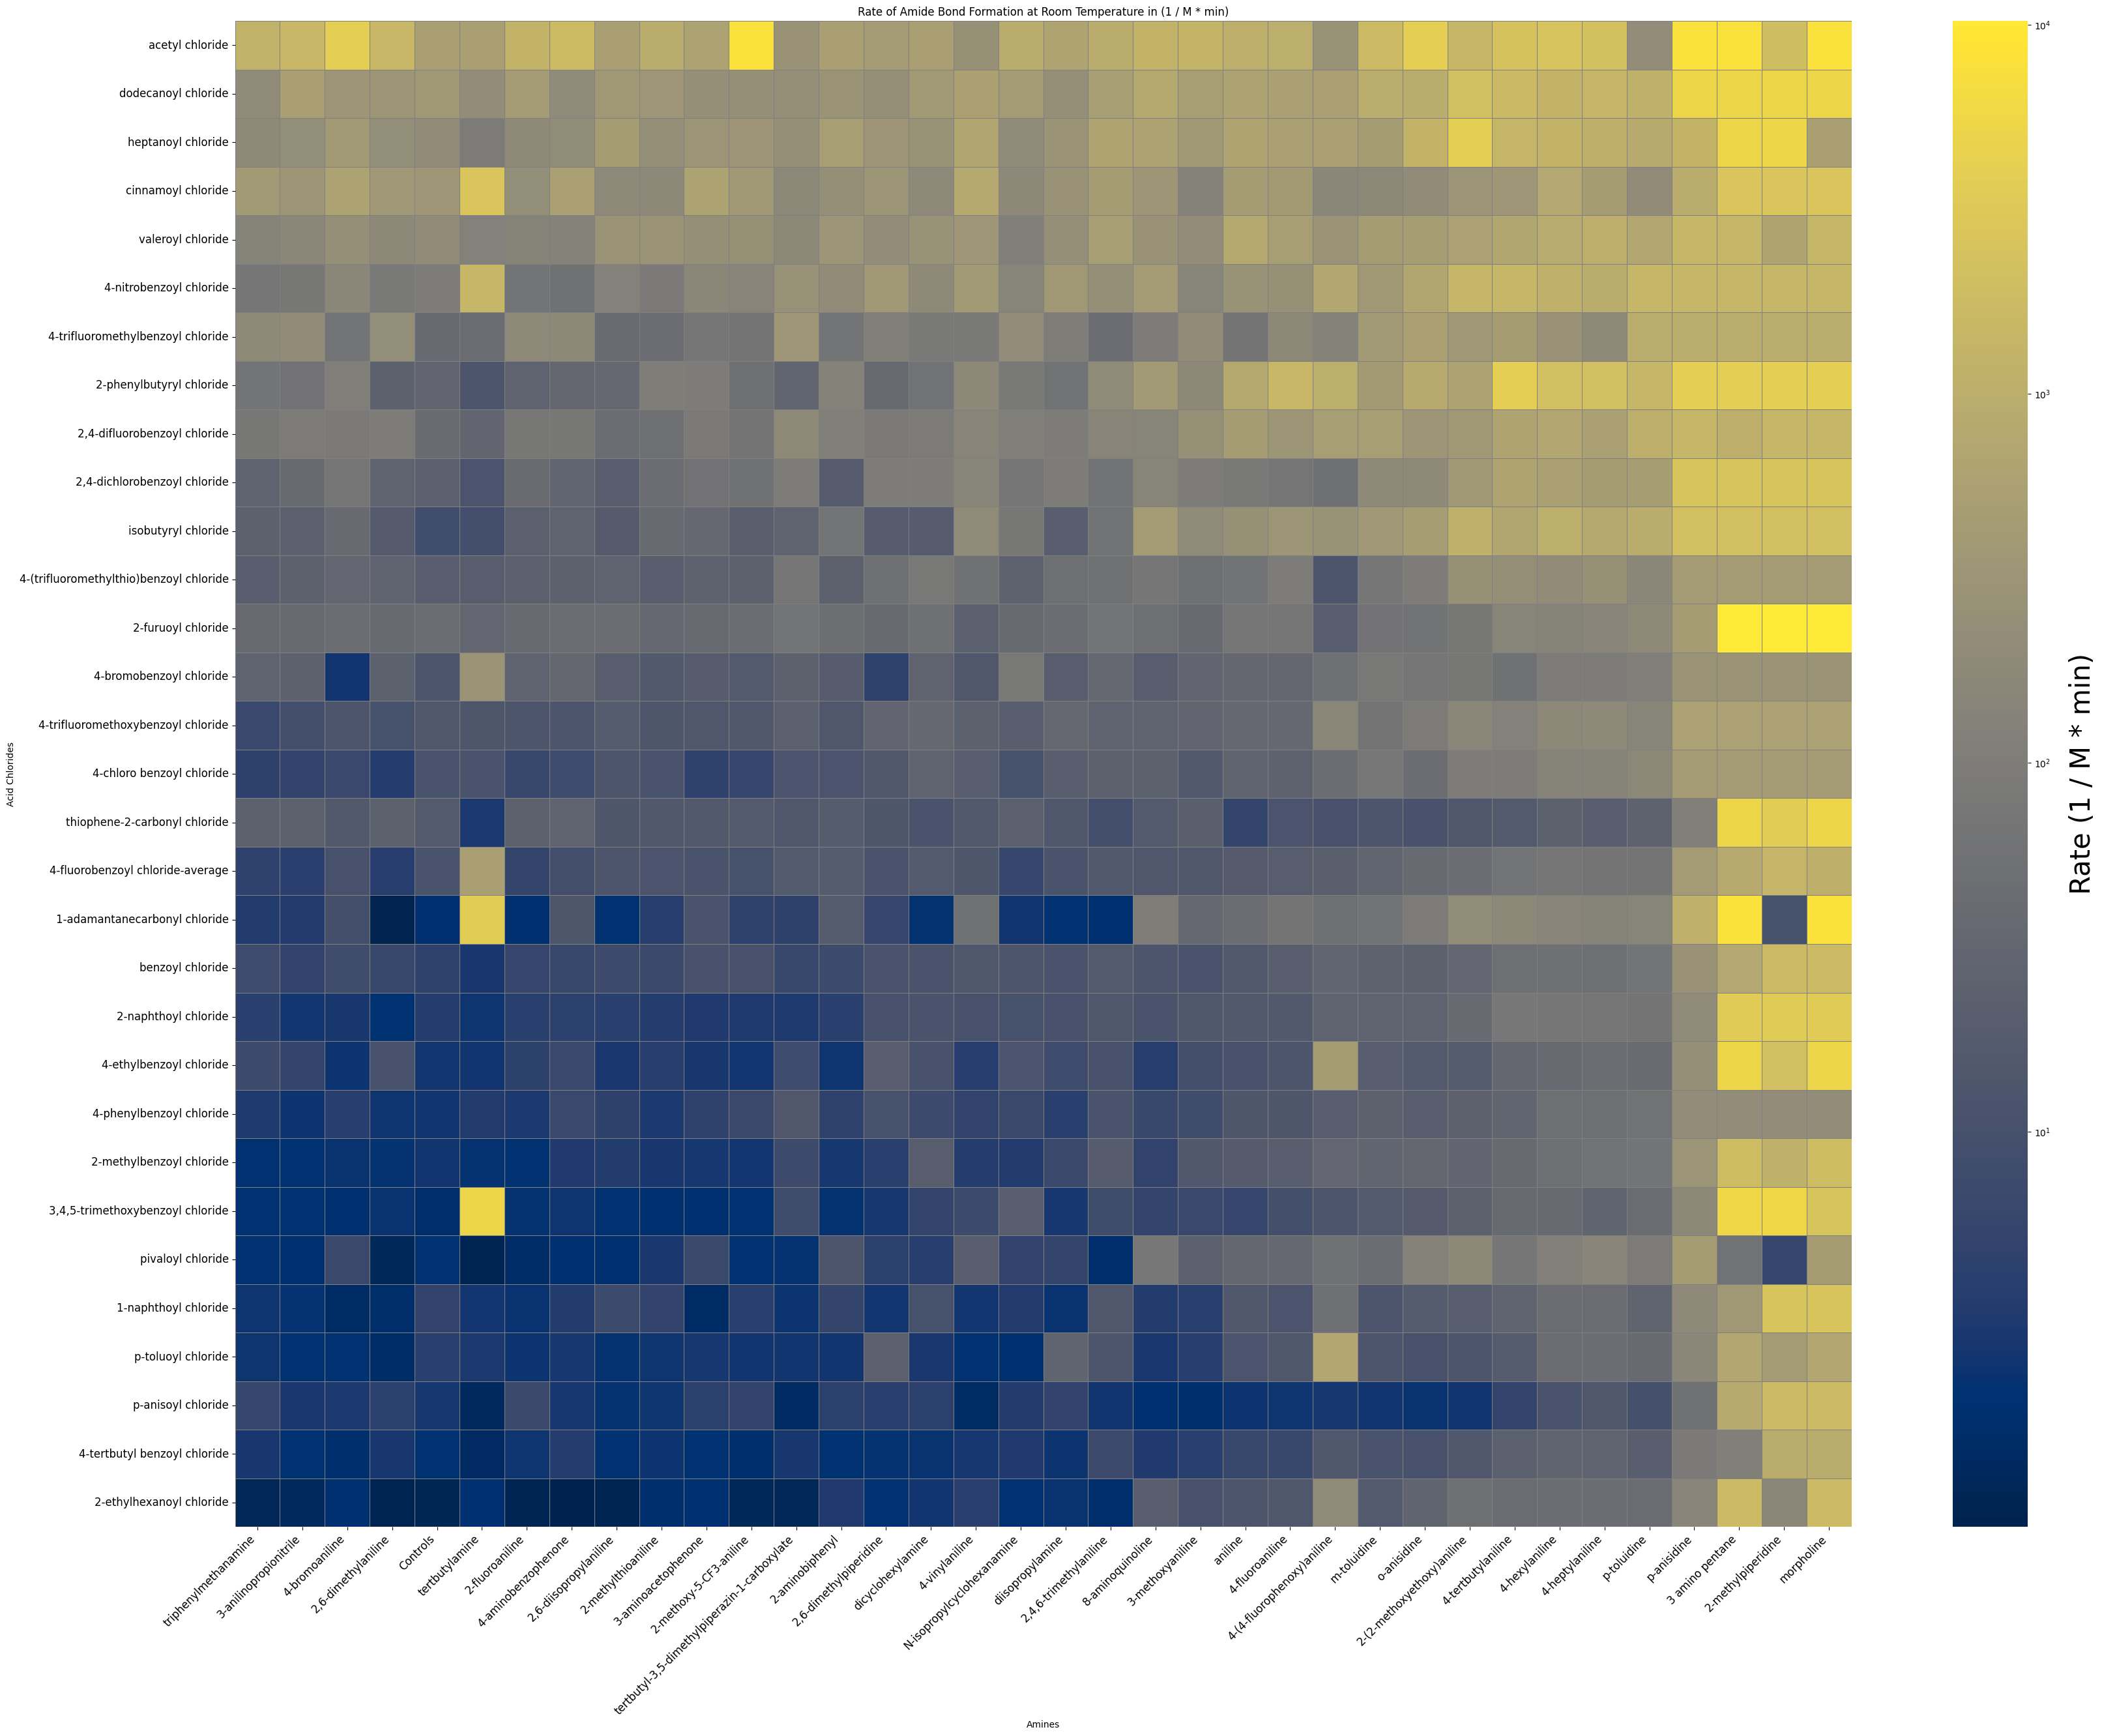

In [14]:
rate_heatmap(sorted_final)

In [15]:
# Get column names (amines)
column_names = sorted_final.columns.tolist()

# Get row names (acid chlorides) 
row_names = sorted_final.index.tolist()

all_names = column_names + row_names

# Convert all_names to a DataFrame and export as CSV
all_names_df = pd.DataFrame(all_names, columns=['names'])
all_names_df.to_csv('all_names.csv', index=False)
